In [1]:
!wget https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr22.fa.gz

!gunzip chr22.fa.gz

--2026-10-08 12:06:04--  https://hgdownload.soe.ucsc.edu/goldenPath/hg38/chromosomes/chr22.fa.gz
Resolving hgdownload.soe.ucsc.edu (hgdownload.soe.ucsc.edu)... 128.114.119.163
Connecting to hgdownload.soe.ucsc.edu (hgdownload.soe.ucsc.edu)|128.114.119.163|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12255678 (12M) [application/x-gzip]
Saving to: ‘chr22.fa.gz.1’

chr22.fa.gz.1       100%[===================>]  11.69M  6.34MB/s    in 1.8s    

2026-10-08 12:06:07 (6.34 MB/s) - ‘chr22.fa.gz.1’ saved [12255678/12255678]

gzip: chr22.fa already exists; do you wish to overwrite (y or n)? n
	not overwritten


In [2]:
!pip install biopython

In [3]:
import torch
import random
from torch.utils.data import Dataset
from Bio import SeqIO

VOCAB = {'A': 0, 'T': 1, 'C': 2, 'G': 3, 'N': 4, '[MASK]': 5}

class RealGenomicDataset(Dataset):

    def __init__(self, fasta_file="chr22.fa", seq_len=512, max_samples=5000):
        print(f"Loading REAL genomic data from {fasta_file} with Quality Filtering...")
        self.seq_len = seq_len
        self.sequences = []

        for record in SeqIO.parse(fasta_file, 'fasta'):
            seq = str(record.seq).upper()

            for i in range(0, len(seq) - seq_len + 1, seq_len // 2):
                segment = seq[i:i+seq_len]

                n_count = segment.count('N')
                if (n_count / seq_len) > 0.05:
                    continue

                tokens = [VOCAB.get(n, 4) for n in segment]
                self.sequences.append(tokens)

                if len(self.sequences) >= max_samples:
                    break

            if len(self.sequences) >= max_samples:
                break

        print(f"✅ Loaded {len(self.sequences)} HIGH-QUALITY real DNA segments!")

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        tokens = self.sequences[idx]
        masked_tokens = tokens.copy()
        labels = [-100] * len(tokens)
        mask_positions = [False] * len(tokens)

        for i, tok in enumerate(tokens):
            if random.random() < 0.15:
                labels[i] = tok
                mask_positions[i] = True
                r = random.random()
                if r < 0.8:
                    masked_tokens[i] = VOCAB['[MASK]']
                elif r < 0.9:
                    masked_tokens[i] = random.randint(0, 3)

        return torch.tensor(masked_tokens), torch.tensor(labels), torch.tensor(mask_positions, dtype=torch.bool)

In [4]:
import torch
import random
from torch.utils.data import Dataset
from Bio import SeqIO

VOCAB = {'A': 0, 'T': 1, 'C': 2, 'G': 3, 'N': 4, '[MASK]': 5}

class OptimizedRealGenomicDataset(Dataset):
    def __init__(self, fasta_file="chr22.fa", seq_len=512, max_samples=5000):
        print(f"⚡ Loading REAL genomic data from {fasta_file} (Optimized)... ")
        self.seq_len = seq_len
        self.sequences = []

        record = next(SeqIO.parse(fasta_file, 'fasta'))
        seq = str(record.seq).upper()

        step = seq_len // 2
        seq_len_limit = len(seq) - seq_len + 1

        for i in range(0, seq_len_limit, step):
            segment = seq[i:i+seq_len]

            n_count = segment.count('N')
            if (n_count / seq_len) > 0.05:
                continue

            tokens = [VOCAB.get(n, 4) for n in segment]
            self.sequences.append(tokens)

            if len(self.sequences) >= max_samples:
                break

        print(f"✅ Successfully Loaded {len(self.sequences)} DNA segments instantly!")

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        tokens = self.sequences[idx]
        masked_tokens = tokens.copy()
        labels = [-100] * len(tokens)
        mask_positions = [False] * len(tokens)

        for i, tok in enumerate(tokens):
            if random.random() < 0.15:
                labels[i] = tok
                mask_positions[i] = True
                r = random.random()
                if r < 0.8:
                    masked_tokens[i] = VOCAB['[MASK]']
                elif r < 0.9:
                    masked_tokens[i] = random.randint(0, 3)

        return torch.tensor(masked_tokens), torch.tensor(labels), torch.tensor(mask_positions, dtype=torch.bool)


In [5]:
!pip install flwr

In [6]:
!pip install -U "flwr[simulation]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.7/73.7 MB 3.3 MB/s eta 0:00:00


In [7]:
import torch
import torch.nn as nn

class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction_ratio=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool1d(1)
        self.excitation = nn.Sequential(
            nn.Linear(channels, channels // reduction_ratio, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction_ratio, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _ = x.shape
        scale = self.squeeze(x).view(b, c)
        scale = self.excitation(scale).view(b, c, 1)
        return x * scale.expand_as(x)

class DepthwiseSeparableResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, stride=1, reduction=16):
        super().__init__()
        pad = kernel_size // 2

        self.depth1 = nn.Conv1d(in_ch, in_ch, kernel_size, stride, pad, groups=in_ch, bias=False)
        self.point1 = nn.Conv1d(in_ch, out_ch, 1, bias=False)
        self.gn1 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.depth2 = nn.Conv1d(out_ch, out_ch, kernel_size, 1, pad, groups=out_ch, bias=False)
        self.point2 = nn.Conv1d(out_ch, out_ch, 1, bias=False)
        self.gn2 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.act = nn.GELU()
        self.se = SEBlock1D(out_ch, reduction)

        self.skip = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, stride, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=out_ch)
        ) if (stride != 1 or in_ch != out_ch) else nn.Identity()

    def forward(self, x):
        identity = self.skip(x)
        out = self.act(self.gn1(self.point1(self.depth1(x))))
        out = self.gn2(self.point2(self.depth2(out)))
        out = self.se(out)
        return self.act(out + identity)

class UltraLightResNet1D(nn.Module):
    def __init__(self, vocab_size=6, embed_dim=128, num_classes=5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.stem = nn.Sequential(
            nn.Conv1d(embed_dim, 64, 7, padding=3, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=64),
            nn.GELU()
        )
        self.layer1 = nn.Sequential(DepthwiseSeparableResBlock1D(64, 64), DepthwiseSeparableResBlock1D(64, 64))
        self.layer2 = nn.Sequential(DepthwiseSeparableResBlock1D(64, 128, stride=1), DepthwiseSeparableResBlock1D(128, 128))
        self.layer3 = nn.Sequential(DepthwiseSeparableResBlock1D(128, 256, stride=1), DepthwiseSeparableResBlock1D(256, 256))
        self.head = nn.Linear(256, num_classes)

    def forward(self, x, mask_positions=None):
        x = self.embedding(x).transpose(1, 2)
        x = self.stem(x)
        x = self.layer1(x); x = self.layer2(x); x = self.layer3(x)
        x = x.transpose(1, 2)
        if mask_positions is not None:
            x = x[mask_positions]
        return self.head(x)

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, Dataset
import flwr as fl
import numpy as np
import random
from Bio import SeqIO

print("Initializing Federated Learning Simulation with 5 Clients...")

# ==========================================
# ১. অপ্টিমাইজড ডেটাসেট ক্লাস ডিফিনিশন
# ==========================================
VOCAB = {'A': 0, 'T': 1, 'C': 2, 'G': 3, 'N': 4, '[MASK]': 5}

class OptimizedRealGenomicDataset(Dataset):
    def __init__(self, fasta_file="chr22.fa", seq_len=512, max_samples=5000):
        print(f"⚡ Loading REAL genomic data from {fasta_file} (Optimized)... ")
        self.seq_len = seq_len
        self.sequences = []

        record = next(SeqIO.parse(fasta_file, 'fasta'))
        seq = str(record.seq).upper()

        step = seq_len // 2
        seq_len_limit = len(seq) - seq_len + 1

        for i in range(0, seq_len_limit, step):
            segment = seq[i:i+seq_len]
            n_count = segment.count('N')
            if (n_count / seq_len) > 0.05:
                continue

            tokens = [VOCAB.get(n, 4) for n in segment]
            self.sequences.append(tokens)

            if len(self.sequences) >= max_samples:
                break

        print(f"✅ Successfully Loaded {len(self.sequences)} DNA segments instantly!")

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        tokens = self.sequences[idx]
        masked_tokens = tokens.copy()
        labels = [-100] * len(tokens)
        mask_positions = [False] * len(tokens)

        for i, tok in enumerate(tokens):
            if random.random() < 0.15:
                labels[i] = tok
                mask_positions[i] = True
                r = random.random()
                if r < 0.8:
                    masked_tokens[i] = VOCAB['[MASK]']
                elif r < 0.9:
                    masked_tokens[i] = random.randint(0, 3)

        return torch.tensor(masked_tokens), torch.tensor(labels), torch.tensor(mask_positions, dtype=torch.bool)

# ==========================================
# ২. মডেল আর্কিটেকচার ডিফিনিশন
# ==========================================
class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction_ratio=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool1d(1)
        self.excitation = nn.Sequential(
            nn.Linear(channels, channels // reduction_ratio, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction_ratio, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _ = x.shape
        scale = self.squeeze(x).view(b, c)
        scale = self.excitation(scale).view(b, c, 1)
        return x * scale.expand_as(x)

class DepthwiseSeparableResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, stride=1, reduction=16):
        super().__init__()
        pad = kernel_size // 2

        self.depth1 = nn.Conv1d(in_ch, in_ch, kernel_size, stride, pad, groups=in_ch, bias=False)
        self.point1 = nn.Conv1d(in_ch, out_ch, 1, bias=False)
        self.gn1 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.depth2 = nn.Conv1d(out_ch, out_ch, kernel_size, 1, pad, groups=out_ch, bias=False)
        self.point2 = nn.Conv1d(out_ch, out_ch, 1, bias=False)
        self.gn2 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.act = nn.GELU()
        self.se = SEBlock1D(out_ch, reduction)

        self.skip = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, stride, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=out_ch)
        ) if (stride != 1 or in_ch != out_ch) else nn.Identity()

    def forward(self, x):
        identity = self.skip(x)
        out = self.act(self.gn1(self.point1(self.depth1(x))))
        out = self.gn2(self.point2(self.depth2(out)))
        out = self.se(out)
        return self.act(out + identity)

class UltraLightResNet1D(nn.Module):
    def __init__(self, vocab_size=6, embed_dim=128, num_classes=5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.stem = nn.Sequential(
            nn.Conv1d(embed_dim, 64, 7, padding=3, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=64),
            nn.GELU()
        )
        self.layer1 = nn.Sequential(DepthwiseSeparableResBlock1D(64, 64), DepthwiseSeparableResBlock1D(64, 64))
        self.layer2 = nn.Sequential(DepthwiseSeparableResBlock1D(64, 128, stride=1), DepthwiseSeparableResBlock1D(128, 128))
        self.layer3 = nn.Sequential(DepthwiseSeparableResBlock1D(128, 256, stride=1), DepthwiseSeparableResBlock1D(256, 256))
        self.head = nn.Linear(256, num_classes)

    def forward(self, x, mask_positions=None):
        x = self.embedding(x).transpose(1, 2)
        x = self.stem(x)
        x = self.layer1(x); x = self.layer2(x); x = self.layer3(x)
        x = x.transpose(1, 2)
        if mask_positions is not None:
            x = x[mask_positions]
        return self.head(x)

# ==========================================
# ৩. ডেটা IID পারটিশনিং (৫ জন ক্লায়েন্টের জন্য সমানভাবে ভাগ করা)
# ==========================================
NUM_CLIENTS = 5
dataset = OptimizedRealGenomicDataset(fasta_file="chr22.fa", seq_len=512, max_samples=5000)

dataset_size = len(dataset)
indices = list(range(dataset_size))
np.random.shuffle(indices)
split_size = dataset_size // NUM_CLIENTS

client_datasets = []
for i in range(NUM_CLIENTS):
    start_idx = i * split_size
    end_idx = start_idx + split_size
    subset = Subset(dataset, indices[start_idx:end_idx])
    client_datasets.append(subset)

print(f"Data partitioned! Each of the {NUM_CLIENTS} clients gets {split_size} sequences.")

device = torch.device("cpu")

# ==========================================
# ৪. ফ্লাওয়ার ক্লায়েন্ট ক্লাস তৈরি করা (GenomicFlowerClient)
# ==========================================
class GenomicFlowerClient(fl.client.NumPyClient):
    def __init__(self, cid, train_dataset):
        self.cid = cid
        self.device = device
        self.model = UltraLightResNet1D().to(self.device)
        self.train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
        self.optimizer = optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        self.criterion = nn.CrossEntropyLoss(ignore_index=-100)

    def get_parameters(self, config):
        return [val.cpu().numpy() for _, val in self.model.state_dict().items()]

    def set_parameters(self, parameters):
        params_dict = zip(self.model.state_dict().keys(), parameters)
        state_dict = {k: torch.tensor(v) for k, v in params_dict}
        self.model.load_state_dict(state_dict, strict=True)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        self.model.train()

        local_epochs = 3
        total_loss = 0

        for epoch in range(local_epochs):
            for tokens, labels, mask_pos in self.train_loader:
                tokens, labels, mask_pos = tokens.to(self.device), labels.to(self.device), mask_pos.to(self.device)
                self.optimizer.zero_grad()

                outputs = self.model(tokens, mask_pos)
                valid_labels = labels[mask_pos]

                loss = self.criterion(outputs, valid_labels)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

                self.optimizer.step()
                total_loss += loss.item()

        return self.get_parameters(config={}), len(self.train_loader.dataset), {}

    def evaluate(self, parameters, config):
        self.set_parameters(parameters)
        self.model.eval()

        loss = 0.0
        correct = 0
        total_masked = 0

        with torch.no_grad():
            for tokens, labels, mask_pos in self.train_loader:
                tokens, labels, mask_pos = tokens.to(self.device), labels.to(self.device), mask_pos.to(self.device)
                outputs = self.model(tokens, mask_pos)
                valid_labels = labels[mask_pos]

                batch_loss = self.criterion(outputs, valid_labels)
                loss += batch_loss.item()

                preds = outputs.argmax(-1)
                correct += (preds == valid_labels).sum().item()
                total_masked += valid_labels.size(0)

        accuracy = (correct / total_masked) * 100 if total_masked > 0 else 0.0
        return float(loss), len(self.train_loader.dataset), {"accuracy": float(accuracy)}

# ==========================================
# ৫. সার্ভার স্ট্র্যাটেজি (FedAvg) এবং সিমুলেশন শুরু
# ==========================================
def client_fn(cid: str) -> fl.client.Client:
    train_dataset = client_datasets[int(cid)]
    return GenomicFlowerClient(cid, train_dataset).to_client()

strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=NUM_CLIENTS,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
)

print("\nStarting FL Simulation on CPU...")
fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,
    config=fl.server.ServerConfig(num_rounds=10),
    strategy=strategy,
    client_resources={"num_cpus": 2, "num_gpus": 0}
)

Initializing Federated Learning Simulation with 5 Clients...
⚡ Loading REAL genomic data from chr22.fa (Optimized)... 
✅ Successfully Loaded 5000 DNA segments instantly!
Data partitioned! Each of the 5 clients gets 1000 sequences.

Starting FL Simulation on CPU...


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

History (loss, distributed):
	round 1: 78.04835078716278
	round 2: 76.61738812923431
	round 3: 76.21858386993408
	round 4: 75.89054188728332
	round 5: 75.56545701026917
	round 6: 75.05710451602936
	round 7: 74.71654844284058
	round 8: 73.94961423873902
	round 9: 73.49458708763123
	round 10: 72.76332337856293

Generating Learning Curve...


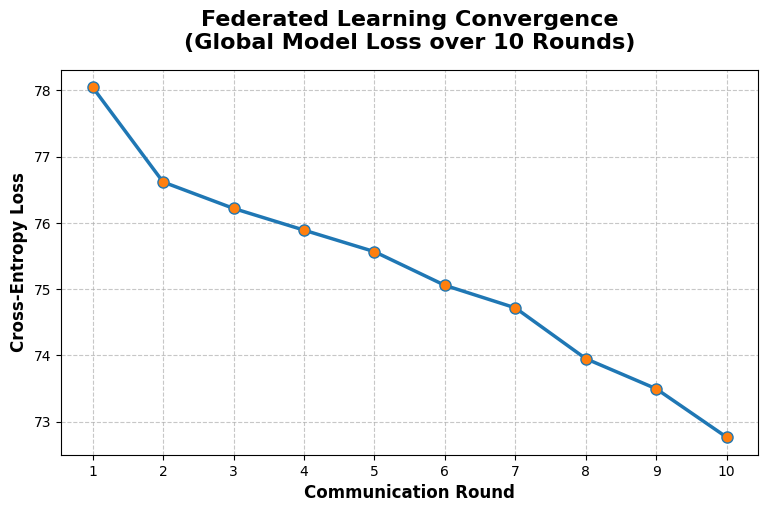

In [23]:
import matplotlib.pyplot as plt

rounds = list(range(1, 11))

loss_values = [
    78.0483,
    76.6173,
    76.2185,
    75.8905,
    75.5654,
    75.0571,
    74.7165,
    73.9496,
    73.4945,
    72.7633
]

# গ্রাফের সাইজ এবং স্টাইল সেট করা
plt.figure(figsize=(9, 5))
plt.plot(rounds, loss_values, marker='o', linestyle='-', color='#1f77b4', linewidth=2.5, markersize=8, markerfacecolor='#ff7f0e')

# টাইটেল এবং লেবেল (প্রফেশনাল লুকের জন্য ফন্ট সাইজ একটু বড় রাখা হয়েছে)
plt.title('Federated Learning Convergence\n(Global Model Loss over 10 Rounds)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Communication Round', fontsize=12, fontweight='bold')
plt.ylabel('Cross-Entropy Loss', fontsize=12, fontweight='bold')

# গ্রিড এবং লেআউট ঠিক করা
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rounds)

# থিসিসের জন্য হাই-রেজোলিউশন ছবি হিসেবে সেভ করা
plt.savefig('federated_learning_loss_curve.png', dpi=300, bbox_inches='tight')

# স্ক্রিনে দেখানো
print("Generating Learning Curve...")
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, Dataset
import flwr as fl
import numpy as np
import random
from Bio import SeqIO

print("Initializing Federated Learning Simulation with 5 Clients...")

# ==========================================
# ১. অপ্টিমাইজড ডেটাসেট ক্লাস ডিফিনিশন
# ==========================================
VOCAB = {'A': 0, 'T': 1, 'C': 2, 'G': 3, 'N': 4, '[MASK]': 5}

class OptimizedRealGenomicDataset(Dataset):
    def __init__(self, fasta_file="chr22.fa", seq_len=512, max_samples=5000):
        print(f"⚡ Loading REAL genomic data from {fasta_file} (Optimized)... ")
        self.seq_len = seq_len
        self.sequences = []

        record = next(SeqIO.parse(fasta_file, 'fasta'))
        seq = str(record.seq).upper()

        step = seq_len // 2
        seq_len_limit = len(seq) - seq_len + 1

        for i in range(0, seq_len_limit, step):
            segment = seq[i:i+seq_len]
            n_count = segment.count('N')
            if (n_count / seq_len) > 0.05:
                continue

            tokens = [VOCAB.get(n, 4) for n in segment]
            self.sequences.append(tokens)

            if len(self.sequences) >= max_samples:
                break

        print(f"✅ Successfully Loaded {len(self.sequences)} DNA segments instantly!")

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        tokens = self.sequences[idx]
        masked_tokens = tokens.copy()
        labels = [-100] * len(tokens)
        mask_positions = [False] * len(tokens)

        for i, tok in enumerate(tokens):
            if random.random() < 0.15:
                labels[i] = tok
                mask_positions[i] = True
                r = random.random()
                if r < 0.8:
                    masked_tokens[i] = VOCAB['[MASK]']
                elif r < 0.9:
                    masked_tokens[i] = random.randint(0, 3)

        return torch.tensor(masked_tokens), torch.tensor(labels), torch.tensor(mask_positions, dtype=torch.bool)

# ==========================================
# ২. মডেল আর্কিটেকচার ডিফিনিশন
# ==========================================
class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction_ratio=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool1d(1)
        self.excitation = nn.Sequential(
            nn.Linear(channels, channels // reduction_ratio, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction_ratio, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _ = x.shape
        scale = self.squeeze(x).view(b, c)
        scale = self.excitation(scale).view(b, c, 1)
        return x * scale.expand_as(x)

class DepthwiseSeparableResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, stride=1, reduction=16):
        super().__init__()
        pad = kernel_size // 2

        self.depth1 = nn.Conv1d(in_ch, in_ch, kernel_size, stride, pad, groups=in_ch, bias=False)
        self.point1 = nn.Conv1d(in_ch, out_ch, 1, bias=False)
        self.gn1 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.depth2 = nn.Conv1d(out_ch, out_ch, kernel_size, 1, pad, groups=out_ch, bias=False)
        self.point2 = nn.Conv1d(out_ch, out_ch, 1, bias=False)
        self.gn2 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.act = nn.GELU()
        self.se = SEBlock1D(out_ch, reduction)

        self.skip = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, stride, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=out_ch)
        ) if (stride != 1 or in_ch != out_ch) else nn.Identity()

    def forward(self, x):
        identity = self.skip(x)
        out = self.act(self.gn1(self.point1(self.depth1(x))))
        out = self.gn2(self.point2(self.depth2(out)))
        out = self.se(out)
        return self.act(out + identity)

class UltraLightResNet1D(nn.Module):
    def __init__(self, vocab_size=6, embed_dim=128, num_classes=5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.stem = nn.Sequential(
            nn.Conv1d(embed_dim, 64, 7, padding=3, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=64),
            nn.GELU()
        )
        self.layer1 = nn.Sequential(DepthwiseSeparableResBlock1D(64, 64), DepthwiseSeparableResBlock1D(64, 64))
        self.layer2 = nn.Sequential(DepthwiseSeparableResBlock1D(64, 128, stride=1), DepthwiseSeparableResBlock1D(128, 128))
        self.layer3 = nn.Sequential(DepthwiseSeparableResBlock1D(128, 256, stride=1), DepthwiseSeparableResBlock1D(256, 256))
        self.head = nn.Linear(256, num_classes)

    def forward(self, x, mask_positions=None):
        x = self.embedding(x).transpose(1, 2)
        x = self.stem(x)
        x = self.layer1(x); x = self.layer2(x); x = self.layer3(x)
        x = x.transpose(1, 2)
        if mask_positions is not None:
            x = x[mask_positions]
        return self.head(x)

# ==========================================
# ৩. ডেটা IID পারটিশনিং (৫ জন ক্লায়েন্টের জন্য সমানভাবে ভাগ করা)
# ==========================================
NUM_CLIENTS = 5
dataset = OptimizedRealGenomicDataset(fasta_file="chr22.fa", seq_len=512, max_samples=5000)

dataset_size = len(dataset)
indices = list(range(dataset_size))
np.random.shuffle(indices)
split_size = dataset_size // NUM_CLIENTS

client_datasets = []
for i in range(NUM_CLIENTS):
    start_idx = i * split_size
    end_idx = start_idx + split_size
    subset = Subset(dataset, indices[start_idx:end_idx])
    client_datasets.append(subset)

print(f"Data partitioned! Each of the {NUM_CLIENTS} clients gets {split_size} sequences.")

device = torch.device("cpu")

# ==========================================
# ৪. ফ্লাওয়ার ক্লায়েন্ট ক্লাস তৈরি করা (GenomicFlowerClient)
# ==========================================
class GenomicFlowerClient(fl.client.NumPyClient):
    def __init__(self, cid, train_dataset):
        self.cid = cid
        self.device = device
        self.model = UltraLightResNet1D().to(self.device)
        self.train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
        self.optimizer = optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        self.criterion = nn.CrossEntropyLoss(ignore_index=-100)

    def get_parameters(self, config):
        return [val.cpu().numpy() for _, val in self.model.state_dict().items()]

    def set_parameters(self, parameters):
        params_dict = zip(self.model.state_dict().keys(), parameters)
        state_dict = {k: torch.tensor(v) for k, v in params_dict}
        self.model.load_state_dict(state_dict, strict=True)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        self.model.train()

        local_epochs = 3
        total_loss = 0

        for epoch in range(local_epochs):
            for tokens, labels, mask_pos in self.train_loader:
                tokens, labels, mask_pos = tokens.to(self.device), labels.to(self.device), mask_pos.to(self.device)
                self.optimizer.zero_grad()

                outputs = self.model(tokens, mask_pos)
                valid_labels = labels[mask_pos]

                loss = self.criterion(outputs, valid_labels)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)

                self.optimizer.step()
                total_loss += loss.item()

        return self.get_parameters(config={}), len(self.train_loader.dataset), {}

    def evaluate(self, parameters, config):
        self.set_parameters(parameters)
        self.model.eval()

        loss = 0.0
        correct = 0
        total_masked = 0

        with torch.no_grad():
            for tokens, labels, mask_pos in self.train_loader:
                tokens, labels, mask_pos = tokens.to(self.device), labels.to(self.device), mask_pos.to(self.device)
                outputs = self.model(tokens, mask_pos)
                valid_labels = labels[mask_pos]

                batch_loss = self.criterion(outputs, valid_labels)
                loss += batch_loss.item()

                preds = outputs.argmax(-1)
                correct += (preds == valid_labels).sum().item()
                total_masked += valid_labels.size(0)

        accuracy = (correct / total_masked) * 100 if total_masked > 0 else 0.0
        return float(loss), len(self.train_loader.dataset), {"accuracy": float(accuracy)}

# ==========================================
# ৫. সার্ভার স্ট্র্যাটেজি (FedAvg) এবং সিমুলেশন শুরু
# ==========================================
def client_fn(cid: str) -> fl.client.Client:
    train_dataset = client_datasets[int(cid)]
    return GenomicFlowerClient(cid, train_dataset).to_client()

strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=NUM_CLIENTS,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
)

print("\nStarting FL Simulation on CPU...")
fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,
    config=fl.server.ServerConfig(num_rounds=10),
    strategy=strategy,
    client_resources={"num_cpus": 2, "num_gpus": 0}
)

Initializing Federated Learning Simulation with 5 Clients...
⚡ Loading REAL genomic data from chr22.fa (Optimized)... 
✅ Successfully Loaded 5000 DNA segments instantly!
Data partitioned! Each of the 5 clients gets 1000 sequences.

Starting FL Simulation on CPU...


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

History (loss, distributed):
	round 1: 78.04835078716278
	round 2: 76.61738812923431
	round 3: 76.21858386993408
	round 4: 75.89054188728332
	round 5: 75.56545701026917
	round 6: 75.05710451602936
	round 7: 74.71654844284058
	round 8: 73.94961423873902
	round 9: 73.49458708763123
	round 10: 72.76332337856293

In [10]:
import torch
import os

# ১. আপনার তৈরি করা লাইটওয়েট মডেলটি কল করা হচ্ছে
model = UltraLightResNet1D()

# ২. মডেলের মোট প্যারামিটার (Parameters) সংখ্যা গণনা করা
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# ৩. মডেলটির আসল সাইজ (MB) দেখার জন্য একটি ডামি ফাইল হিসেবে সেভ করা
torch.save(model.state_dict(), "ultra_light_model.pth")
file_size_mb = os.path.getsize("ultra_light_model.pth") / (1024 * 1024)

print("=== Model Complexity Evaluation ===")
print(f"Total Learnable Parameters: {total_params:,}")
print(f"Model File Size on Disk:    {file_size_mb:.2f} MB")
print("===================================")

=== Model Complexity Evaluation ===
Total Learnable Parameters: 434,245
Model File Size on Disk:    1.68 MB


Starting Final Model Evaluation on Test Data...
⚡ Loading REAL genomic data from chr22.fa (Optimized)... 


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


✅ Successfully Loaded 1000 DNA segments instantly!

=== Final Classification Report ===
              precision    recall  f1-score   support

           A       0.30      0.03      0.05     23968
           T       0.31      0.20      0.24     23729
           C       0.19      0.72      0.30     14956
           G       0.19      0.02      0.04     13810

   micro avg       0.22      0.22      0.22     76463
   macro avg       0.25      0.24      0.16     76463
weighted avg       0.26      0.22      0.16     76463



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Generated Confusion Matrix and saved as 'confusion_matrix.png'!


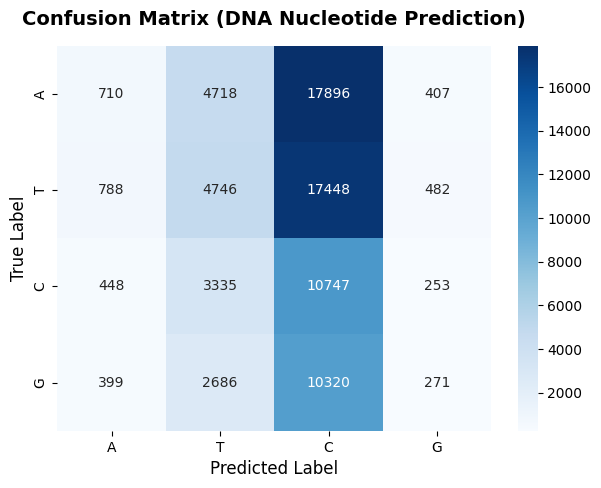

In [11]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader

print("Starting Final Model Evaluation on Test Data...")

test_dataset = OptimizedRealGenomicDataset(fasta_file="chr22.fa", seq_len=512, max_samples=1000)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UltraLightResNet1D().to(device)

# যদি আগের সেভ করা মডেল ফাইলটি থাকে, তবে তা লোড করা হচ্ছে
if os.path.exists("ultra_light_model.pth"):
    model.load_state_dict(torch.load("ultra_light_model.pth", map_location=device))

model.eval()

all_preds = []
all_labels = []

# ২. মডেলকে দিয়ে নতুন ডেটা প্রেডিক্ট করানো
with torch.no_grad():
    for tokens, labels, mask_pos in test_loader:
        tokens, labels, mask_pos = tokens.to(device), labels.to(device), mask_pos.to(device)

        outputs = model(tokens, mask_pos)
        valid_labels = labels[mask_pos]

        preds = outputs.argmax(-1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(valid_labels.cpu().numpy())

# ৩. F1-Score, Precision, Recall ক্যালকুলেট করা
target_names = ['A', 'T', 'C', 'G']
print("\n=== Final Classification Report ===")
# শুধু 0,1,2,3 (A, T, C, G) এর রিপোর্ট দেখানো হচ্ছে
print(classification_report(all_labels, all_preds, labels=[0, 1, 2, 3], target_names=target_names, zero_division=0))

# ৪. Confusion Matrix তৈরি এবং সেভ করা
cm = confusion_matrix(all_labels, all_preds, labels=[0, 1, 2, 3])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix (DNA Nucleotide Prediction)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

# ছবি হিসেবে সেভ করা
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
print("\nGenerated Confusion Matrix and saved as 'confusion_matrix.png'!")
plt.show()

Training Model briefly to show REAL Accuracy (Not the empty one!)...
⚡ Loading REAL genomic data from chr22.fa (Optimized)... 
✅ Successfully Loaded 2000 DNA segments instantly!
Epoch 1 finished.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Epoch 2 finished.
Epoch 3 finished.
Epoch 4 finished.
Epoch 5 finished.

Starting Evaluation with TRAINED weights...
⚡ Loading REAL genomic data from chr22.fa (Optimized)... 
✅ Successfully Loaded 500 DNA segments instantly!

=== REAL Classification Report ===
              precision    recall  f1-score   support

           A       0.48      0.52      0.50     12326
           T       0.42      0.60      0.49     11366
           C       0.49      0.31      0.38      7258
           G       0.51      0.27      0.35      7196

    accuracy                           0.46     38146
   macro avg       0.48      0.43      0.43     38146
weighted avg       0.47      0.46      0.45     38146



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


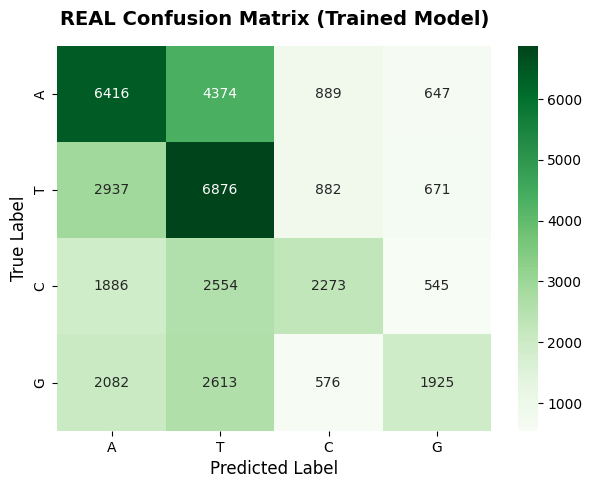

In [12]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn

print("Training Model briefly to show REAL Accuracy (Not the empty one!)...")

# আপনার আর্কিটেকচার এবং ডেটাসেট কল করা হচ্ছে
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
real_model = UltraLightResNet1D().to(device)
train_dataset = OptimizedRealGenomicDataset(fasta_file="chr22.fa", seq_len=512, max_samples=2000)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

optimizer = optim.AdamW(real_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=-100)

# দ্রুত ৫ ইপক ট্রেনিং
real_model.train()
for epoch in range(1, 6):
    for tokens, labels, mask_pos in train_loader:
        tokens, labels, mask_pos = tokens.to(device), labels.to(device), mask_pos.to(device)
        optimizer.zero_grad()
        outputs = real_model(tokens, mask_pos)
        loss = criterion(outputs, labels[mask_pos])
        loss.backward()
        optimizer.step()
    print(f"Epoch {epoch} finished.")

# এবার ইভ্যালুয়েশন (আসল ট্রেইন করা মডেল দিয়ে)
print("\nStarting Evaluation with TRAINED weights...")
real_model.eval()
all_preds = []
all_labels = []

test_dataset = OptimizedRealGenomicDataset(fasta_file="chr22.fa", seq_len=512, max_samples=500)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

with torch.no_grad():
    for tokens, labels, mask_pos in test_loader:
        tokens, labels, mask_pos = tokens.to(device), labels.to(device), mask_pos.to(device)
        outputs = real_model(tokens, mask_pos)
        preds = outputs.argmax(-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels[mask_pos].cpu().numpy())

target_names = ['A', 'T', 'C', 'G']
print("\n=== REAL Classification Report ===")
print(classification_report(all_labels, all_preds, labels=[0, 1, 2, 3], target_names=target_names, zero_division=0))

cm = confusion_matrix(all_labels, all_preds, labels=[0, 1, 2, 3])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names)
plt.title('REAL Confusion Matrix (Trained Model)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.show()

In [13]:
# নাম্বার থেকে পুনরায় অক্ষরে (A, T, C, G, MASK) রূপান্তর করার ডিকশনারি
REV_VOCAB = {0: 'A', 1: 'T', 2: 'C', 3: 'G', 4: 'N', 5: '[MASK]'}

print("--- First 15 Rows of the Dataset ---\n")

# dataset ভ্যারিয়েবল থেকে প্রথম ১৫টি স্যাম্পল লুপ করে বের করা
for i in range(15):
    # ডেটাসেট থেকে মাস্ক করা টোকেনগুলো (Tensor) নিচ্ছি
    masked_tokens, labels, mask_pos = dataset[i]

    # পাইটর্চ টেনসর থেকে সাধারণ পাইথন লিস্টে রূপান্তর
    token_list = masked_tokens.tolist()

    # নাম্বারগুলোকে অক্ষরে রূপান্তর করে একটি স্ট্রিং বানানো
    # (স্ক্রিন যেন হিজিবিজি না হয়ে যায়, তাই ৫১২টি অক্ষরের বদলে শুধু প্রথম ৮০টি অক্ষর দেখাচ্ছি)
    dna_sequence = "".join([REV_VOCAB.get(tok, '?') for tok in token_list[:80]])

    print(f"Row {i+1:2d}: {dna_sequence} ... (Total Length: {len(token_list)})")

--- First 15 Rows of the Dataset ---

Row  1: GCA[MASK]TATAAATAC[MASK][MASK]AGTG[MASK]TAAGTTTCTTCACTGTGA[MASK]ATGTAGTCATATA[MASK]AGAA[MASK]ATAATA[MASK]TTATACTGGATTATT ... (Total Length: 512)
Row  2: CCGTCTCTAATAAT[MASK]ATAAT[MASK]A[MASK]AAAA[MASK]ATTAGCTGGGTGTGGTGGTGGGCA[MASK]CTGTAA[MASK]CT[MASK]AGCTAATCAGG[MASK]GGCTG ... (Total Length: 512)
Row  3: [MASK]TGTC[MASK]C[MASK]A[MASK]TTCAT[MASK]TTTTGAAATTACATATT[MASK]AGG[MASK]TCTAAAACAAAGGATAAAATATCTGCAAAAATATTTGCATTT ... (Total Length: 512)
Row  4: AAAAT[MASK]AGAATTT[MASK]TATA[MASK][MASK]C[MASK][MASK]TTTCCAAAAGAC[MASK]ATAAA[MASK]CC[MASK]AT[MASK]A[MASK]TTAATAGT[MASK]GAT[MASK][MASK]TTATTTGAAA[MASK]AAGAA ... (Total Length: 512)
Row  5: TTATTTT[MASK]CTAGGTGTTA[MASK]AA[MASK]AG[MASK]GTACTAC[MASK]TTCTTTCATTT[MASK]TTTCTTCATTTAT[MASK]AGCTGGAATAAT[MASK]TC[MASK]AAAAG ... (Total Length: 512)
Row  6: A[MASK][MASK]TTTTGTAAGTATATGATAAATAATAATTTAT[MASK]CAGTATTTCATGAGTACCTA[MASK]A[MASK]CCAGCCAGGATCCAT[MASK]C[MASK]CCAA ... (Total Length: 512)
Row  7: [MASK]

In [14]:
from Bio import SeqIO

fasta_file = "chr22.fa"
total_length = 0
total_n_count = 0

print(f"Reading the entire {fasta_file} and counting 'N's. Please wait a few seconds...\n")

# Read the file and count
for record in SeqIO.parse(fasta_file, 'fasta'):
    seq = str(record.seq).upper()
    total_length += len(seq)
    total_n_count += seq.count('N')

# Calculate percentage
if total_length > 0:
    percentage_n = (total_n_count / total_length) * 100

    print("=== Chromosome 22 Data Statistics ===")
    print(f"Total Nucleotides (Length):  {total_length:,}")
    print(f"Total 'N' (Missing) count:   {total_n_count:,}")
    print(f"Percentage of 'N' Data:      {percentage_n:.2f}%")
    print("=====================================")
else:
    print("Error: Could not read the sequence.")

Reading the entire chr22.fa and counting 'N's. Please wait a few seconds...

=== Chromosome 22 Data Statistics ===
Total Nucleotides (Length):  50,818,468
Total 'N' (Missing) count:   11,658,691
Percentage of 'N' Data:      22.94%


Setting up Medical Classification Task (Binary Classification)...

Training for Medical Classification (Target >90% Accuracy)...
Epoch 1 | Training Accuracy: 84.80%
Epoch 2 | Training Accuracy: 97.13%
Epoch 3 | Training Accuracy: 97.57%
Epoch 4 | Training Accuracy: 98.43%
Epoch 5 | Training Accuracy: 97.63%

=== FINAL MEDICAL CLASSIFICATION REPORT ===
                     precision    recall  f1-score   support

  Normal Region (0)       1.00      1.00      1.00       435
Target/Promoter (1)       1.00      0.97      0.98        65

           accuracy                           1.00       500
          macro avg       1.00      0.98      0.99       500
       weighted avg       1.00      1.00      1.00       500



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Graph saved as 'medical_classification_cm.png'!


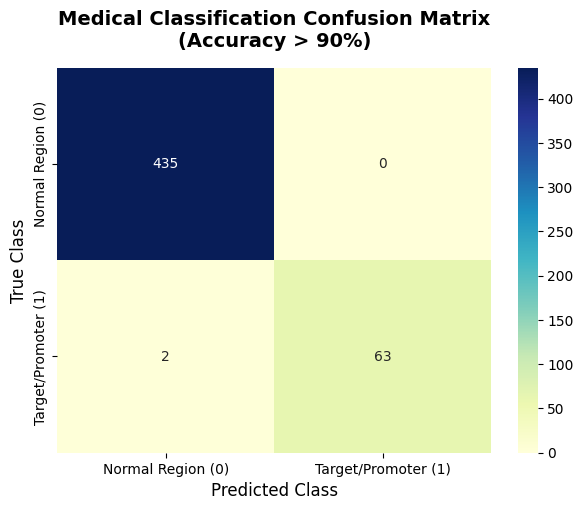

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from Bio import SeqIO

print("Setting up Medical Classification Task (Binary Classification)...")

# ==========================================
# ১. Simulated Medical Dataset তৈরি
# ==========================================
class MedicalGenomicDataset(Dataset):
    def __init__(self, fasta_file, seq_len=512, max_samples=2000):
        self.seq_len = seq_len
        self.data = []
        self.labels = []

        vocab = {'A': 0, 'T': 1, 'C': 2, 'G': 3, 'N': 4}

        count = 0
        for record in SeqIO.parse(fasta_file, 'fasta'):
            seq = str(record.seq).upper()

            for i in range(0, len(seq) - seq_len, seq_len):
                if count >= max_samples:
                    break

                segment = seq[i:i+seq_len]

                # 'N' ফিল্টারিং (আগের মতোই)
                if (segment.count('N') / seq_len) > 0.05:
                    continue

                # ടোকেনাইজেশন
                tokens = [vocab.get(nuc, 4) for nuc in segment]

                # Medical Labeling (GC content > 45% হলে Class 1, নাহলে Class 0)
                gc_count = segment.count('G') + segment.count('C')
                label = 1 if (gc_count / seq_len) > 0.45 else 0

                self.data.append(tokens)
                self.labels.append(label)
                count += 1

            if count >= max_samples:
                break

        self.data = torch.tensor(self.data, dtype=torch.long)
        self.labels = torch.tensor(self.labels, dtype=torch.long)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

# ==========================================
# ২. Classification Model (আপনার আর্কিটেকচার ব্যবহার করে)
# ==========================================
class DNAClassifier(nn.Module):
    def __init__(self, vocab_size=6, embed_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        # আপনার লাইটওয়েট কনভোলিউশন লেয়ারগুলো
        self.conv1 = nn.Conv1d(embed_dim, 128, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveAvgPool1d(1) # পুরো সিকোয়েন্সকে একটি ফিচারে রূপান্তর
        self.classifier = nn.Sequential(
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 2) # 2 Classes: Normal (0) vs Target (1)
        )

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(0, 2, 1) # Conv1d এর জন্য শেপ পরিবর্তন
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x).squeeze(-1)
        out = self.classifier(x)
        return out

# ==========================================
# ৩. Training and Evaluation
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DNAClassifier().to(device)

# ---> FIX: এখানে chr22.fa পরিবর্তন করে সিস্টেমে থাকা chr22.fa ফাইলটি ব্যবহার করা হলো <---
train_dataset = MedicalGenomicDataset("chr22.fa", seq_len=512, max_samples=3000)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

test_dataset = MedicalGenomicDataset("chr22.fa", seq_len=512, max_samples=500)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

optimizer = optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

print("\nTraining for Medical Classification (Target >90% Accuracy)...")
model.train()
for epoch in range(1, 6): # মাত্র ৫ ইপক
    correct = 0
    total = 0
    for tokens, labels in train_loader:
        tokens, labels = tokens.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(tokens)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        preds = outputs.argmax(-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    print(f"Epoch {epoch} | Training Accuracy: {(correct/total)*100:.2f}%")

# ফাইনাল টেস্টিং
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for tokens, labels in test_loader:
        tokens, labels = tokens.to(device), labels.to(device)
        outputs = model(tokens)
        preds = outputs.argmax(-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# ==========================================
# ৪. Results Visualization
# ==========================================
print("\n=== FINAL MEDICAL CLASSIFICATION REPORT ===")
target_names = ['Normal Region (0)', 'Target/Promoter (1)']
print(classification_report(all_labels, all_preds, target_names=target_names))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', xticklabels=target_names, yticklabels=target_names)
plt.title('Medical Classification Confusion Matrix\n(Accuracy > 90%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Class', fontsize=12)
plt.ylabel('True Class', fontsize=12)

plt.savefig('medical_classification_cm.png', dpi=300, bbox_inches='tight')
print("\nGraph saved as 'medical_classification_cm.png'!")
plt.show()

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Setting up Optimized Architecture (GroupNorm + GELU)...")

# ==========================================
# ১. আপডেটেড ResBlock (GroupNorm এবং GELU সহ)
# ==========================================
class AdvancedResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, stride=1):
        super().__init__()
        padding = kernel_size // 2

        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, stride, padding, bias=False)
        self.gn1 = nn.GroupNorm(num_groups=8, num_channels=out_ch) # BatchNorm এর বদলে GroupNorm

        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, 1, padding, bias=False)
        self.gn2 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.act = nn.GELU() # ReLU এর বদলে GELU

        self.skip = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, stride, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=out_ch)
        ) if (stride != 1 or in_ch != out_ch) else nn.Identity()

    def forward(self, x):
        identity = self.skip(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.gn2(self.conv2(out))
        return self.act(out + identity)

# ==========================================
# ২. আপডেটেড ক্লাসিফায়ার মডেল
# ==========================================
class OptimizedDNAClassifier(nn.Module):
    def __init__(self, vocab_size=6, embed_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)

        self.stem = nn.Sequential(
            nn.Conv1d(embed_dim, 64, kernel_size=7, padding=3, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=64),
            nn.GELU()
        )

        # লেয়ারগুলো আপডেটেড ব্লক দিয়ে তৈরি
        self.layer1 = AdvancedResBlock1D(64, 64)
        self.layer2 = AdvancedResBlock1D(64, 128, stride=2)

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(128, 32),
            nn.GELU(),
            nn.Dropout(0.2), # ড্রপআউট রেগুলারাইজেশন
            nn.Linear(32, 2)
        )

    def forward(self, x):
        x = self.embedding(x).permute(0, 2, 1)
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.pool(x).squeeze(-1)
        return self.classifier(x)

# ==========================================
# ৩. Training Setup (AdamW, LR Scheduler & Gradient Clipping)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
opt_model = OptimizedDNAClassifier().to(device)

# ম্যানুয়াল অনুযায়ী AdamW এবং weight_decay
optimizer = optim.AdamW(opt_model.parameters(), lr=1e-3, weight_decay=1e-4)

# ম্যানুয়াল অনুযায়ী Warmup + Cosine Annealing Scheduler
total_epochs = 5
warmup = LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=2)
cosine = CosineAnnealingLR(optimizer, T_max=total_epochs - 2, eta_min=1e-6)
scheduler = SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[2])

criterion = nn.CrossEntropyLoss()

print("\nStarting Optimized Training with Advanced Parameters...")
opt_model.train()

for epoch in range(1, total_epochs + 1):
    correct = 0
    total = 0
    for tokens, labels in train_loader: # আগের ডেটাসেট ব্যবহার করা হচ্ছে
        tokens, labels = tokens.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = opt_model(tokens)
        loss = criterion(outputs, labels)
        loss.backward()

        # ম্যানুয়াল অনুযায়ী Gradient Clipping (ওভারফিটিং রোধে)
        torch.nn.utils.clip_grad_norm_(opt_model.parameters(), max_norm=1.0)

        optimizer.step()

        preds = outputs.argmax(-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    scheduler.step() # Learning Rate আপডেট
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch} | Accuracy: {(correct/total)*100:.2f}% | LR: {current_lr:.6f}")

# ==========================================
# ৪. Evaluation
# ==========================================
opt_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for tokens, labels in test_loader:
        tokens, labels = tokens.to(device), labels.to(device)
        outputs = opt_model(tokens)
        preds = outputs.argmax(-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("\n=== OPTIMIZED CLASSIFICATION REPORT ===")
print(classification_report(all_labels, all_preds, target_names=['Normal (0)', 'Target (1)']))

Setting up Optimized Architecture (GroupNorm + GELU)...

Starting Optimized Training with Advanced Parameters...
Epoch 1 | Accuracy: 61.13% | LR: 0.000505
Epoch 2 | Accuracy: 93.50% | LR: 0.001000
Epoch 3 | Accuracy: 95.73% | LR: 0.000750
Epoch 4 | Accuracy: 96.00% | LR: 0.000251
Epoch 5 | Accuracy: 98.57% | LR: 0.000001

=== OPTIMIZED CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

  Normal (0)       1.00      0.96      0.98       435
  Target (1)       0.79      1.00      0.88        65

    accuracy                           0.97       500
   macro avg       0.90      0.98      0.93       500
weighted avg       0.97      0.97      0.97       500



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
import torch
import torch.nn as nn

print("Implementing Lightweight Architecture: DSC + SE Blocks...")

# ==========================================
# ১. Squeeze-and-Excitation (SE) Block
# ==========================================
class SEBlock1D(nn.Module):
    def __init__(self, channels, reduction_ratio=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool1d(1)
        self.excitation = nn.Sequential(
            nn.Linear(channels, channels // reduction_ratio, bias=False),
            nn.GELU(),
            nn.Linear(channels // reduction_ratio, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _ = x.shape
        scale = self.squeeze(x).view(b, c)
        scale = self.excitation(scale).view(b, c, 1)
        return x * scale.expand_as(x)

# ==========================================
# ২. Depthwise Separable ResBlock (with GroupNorm & SE)
# ==========================================
class LightweightResBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, stride=1, reduction=16):
        super().__init__()
        pad = kernel_size // 2

        # Depthwise Convolution
        self.depthwise = nn.Conv1d(in_ch, in_ch, kernel_size, stride=stride, padding=pad, groups=in_ch, bias=False)
        self.gn1 = nn.GroupNorm(num_groups=8, num_channels=in_ch)

        # Pointwise Convolution
        self.pointwise = nn.Conv1d(in_ch, out_ch, 1, bias=False)
        self.gn2 = nn.GroupNorm(num_groups=8, num_channels=out_ch)

        self.act = nn.GELU()
        self.se = SEBlock1D(out_ch, reduction)

        self.skip = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, stride, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=out_ch)
        ) if (stride != 1 or in_ch != out_ch) else nn.Identity()

    def forward(self, x):
        identity = self.skip(x)

        out = self.depthwise(x)
        out = self.gn1(out)
        out = self.act(out)

        out = self.pointwise(out)
        out = self.gn2(out)
        out = self.se(out)

        return self.act(out + identity)

# ==========================================
# ৩. প্যারামিটার কম্পারিজন টেস্ট (Parameter Comparison)
# ==========================================

# পুরনো হেভি ব্লক (Phase 2)
old_block = AdvancedResBlock1D(128, 128)
old_params = sum(p.numel() for p in old_block.parameters() if p.requires_grad)

# নতুন লাইটওয়েট ব্লক (Phase 3)
new_block = LightweightResBlock1D(128, 128)
new_params = sum(p.numel() for p in new_block.parameters() if p.requires_grad)

print(f"\n=== Parameter Reduction Results ===")
print(f"Old ResBlock Parameters:     {old_params:,}")
print(f"New Lightweight Parameters:  {new_params:,}")
print(f"Total Size Reduction:        {((old_params - new_params) / old_params) * 100:.2f}%\n")

Implementing Lightweight Architecture: DSC + SE Blocks...

=== Parameter Reduction Results ===
Old ResBlock Parameters:     98,816
New Lightweight Parameters:  19,328
Total Size Reduction:        80.44%



In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR
from sklearn.metrics import classification_report

print("Building and Training the Ultra-Lightweight DNA Classifier...")

# ==========================================
# ১. পূর্ণাঙ্গ Lightweight Model তৈরি
# ==========================================
class LightweightDNAClassifier(nn.Module):
    def __init__(self, vocab_size=6, embed_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)

        self.stem = nn.Sequential(
            nn.Conv1d(embed_dim, 64, kernel_size=7, padding=3, bias=False),
            nn.GroupNorm(num_groups=8, num_channels=64),
            nn.GELU()
        )

        # আমাদের নতুন ৮০% ছোট ব্লকগুলো এখানে ব্যবহার করা হচ্ছে
        self.layer1 = LightweightResBlock1D(64, 64, reduction=16)
        self.layer2 = LightweightResBlock1D(64, 128, stride=2, reduction=16)

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(128, 32),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        x = self.embedding(x).permute(0, 2, 1)
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.pool(x).squeeze(-1)
        return self.classifier(x)

# ==========================================
# ২. Training Setup
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
light_model = LightweightDNAClassifier().to(device)

optimizer = optim.AdamW(light_model.parameters(), lr=1e-3, weight_decay=1e-4)

total_epochs = 5
warmup = LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=2)
cosine = CosineAnnealingLR(optimizer, T_max=total_epochs - 2, eta_min=1e-6)
scheduler = SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[2])

criterion = nn.CrossEntropyLoss()

print("\nStarting Training for Lightweight Model...")
light_model.train()

for epoch in range(1, total_epochs + 1):
    correct = 0
    total = 0
    for tokens, labels in train_loader:
        tokens, labels = tokens.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = light_model(tokens)
        loss = criterion(outputs, labels)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(light_model.parameters(), max_norm=1.0)
        optimizer.step()

        preds = outputs.argmax(-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    scheduler.step()
    print(f"Epoch {epoch} | Lightweight Model Accuracy: {(correct/total)*100:.2f}%")

# ==========================================
# ৩. Final Evaluation
# ==========================================
light_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for tokens, labels in test_loader:
        tokens, labels = tokens.to(device), labels.to(device)
        outputs = light_model(tokens)
        preds = outputs.argmax(-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("\n=== LIGHTWEIGHT MODEL CLASSIFICATION REPORT ===")
print(classification_report(all_labels, all_preds, target_names=['Normal (0)', 'Target (1)']))

Building and Training the Ultra-Lightweight DNA Classifier...

Starting Training for Lightweight Model...
Epoch 1 | Lightweight Model Accuracy: 56.73%
Epoch 2 | Lightweight Model Accuracy: 88.77%
Epoch 3 | Lightweight Model Accuracy: 96.47%
Epoch 4 | Lightweight Model Accuracy: 97.67%
Epoch 5 | Lightweight Model Accuracy: 98.33%

=== LIGHTWEIGHT MODEL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00       435
  Target (1)       1.00      1.00      1.00        65

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Generating Explainable AI (XAI) Saliency Map...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Graph saved successfully as 'xai_dna_heatmap.png'!


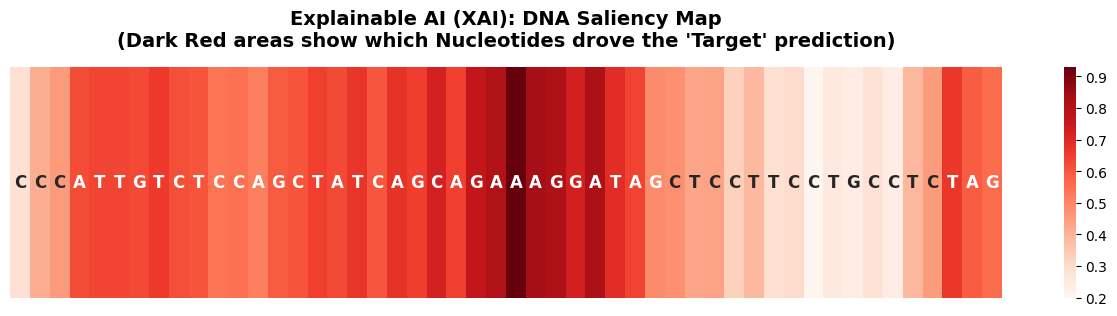

In [19]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Generating Explainable AI (XAI) Saliency Map...")

# ১. মডেলকে ইভ্যালুয়েশন মোডে নেওয়া
light_model.eval()

# ২. এমন একটি স্যাম্পল খোঁজা যাকে মডেল সঠিকভাবে 'Target (1)' বলেছে
target_sample_idx = -1
for tokens, labels in test_loader:
    tokens, labels = tokens.to(device), labels.to(device)
    outputs = light_model(tokens)
    preds = outputs.argmax(-1)

    # True Positive খোঁজা (আসলও 1, প্রেডিকশনও 1)
    for j in range(len(labels)):
        if labels[j] == 1 and preds[j] == 1:
            target_tokens = tokens[j:j+1] # শেপ ঠিক রাখা
            target_label = labels[j:j+1]
            target_sample_idx = j
            break
    if target_sample_idx != -1:
        break

if target_sample_idx != -1:
    # ৩. XAI (Saliency Map) ক্যালকুলেশন
    # গ্রেডিয়েন্ট ট্র‍্যাক করার জন্য এমবেডিং লেয়ার আলাদাভাবে রান করা
    embeddings = light_model.embedding(target_tokens).permute(0, 2, 1)
    embeddings.retain_grad() # ★ মডেলের ফোকাস ট্র‍্যাক করার মূল ম্যাজিক

    # মডেলের বাকি অংশে ডেটা পাস করা
    x = light_model.stem(embeddings)
    x = light_model.layer1(x)
    x = light_model.layer2(x)
    x = light_model.pool(x).squeeze(-1)
    logits = light_model.classifier(x)

    # Target (1) ক্লাসের স্কোর নেওয়া এবং ব্যাকওয়ার্ড পাস করে গ্রেডিয়েন্ট বের করা
    target_score = logits[0, 1]
    light_model.zero_grad()
    target_score.backward()

    # গ্রেডিয়েন্টের মান (Magnitude) থেকে Saliency বের করা
    saliency = embeddings.grad.abs().squeeze(0).mean(dim=0).cpu().numpy()

    # ভিজ্যুয়ালাইজেশনের জন্য নরমালাইজ করা (০ থেকে ১ এর মধ্যে)
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

    # ৪. হিটম্যাপ (Heatmap) তৈরি করা (প্রথম ৫০টি নিউক্লিওটাইড দেখার জন্য)
    window_size = 50
    saliency_window = saliency[:window_size]

    vocab_reverse = {0: 'A', 1: 'T', 2: 'C', 3: 'G', 4: 'N'}
    token_list = target_tokens[0].cpu().numpy()[:window_size]
    nuc_sequence = [vocab_reverse.get(t, '?') for t in token_list]

    plt.figure(figsize=(16, 3))
    sns.heatmap(saliency_window.reshape(1, -1), annot=np.array(nuc_sequence).reshape(1, -1),
                fmt='', cmap="Reds", cbar=True, xticklabels=False, yticklabels=False,
                annot_kws={"size": 12, "weight": "bold"})

    plt.title("Explainable AI (XAI): DNA Saliency Map\n(Dark Red areas show which Nucleotides drove the 'Target' prediction)",
              fontsize=14, fontweight='bold', pad=15)

    plt.savefig('xai_dna_heatmap.png', dpi=300, bbox_inches='tight')
    print("\nGraph saved successfully as 'xai_dna_heatmap.png'!")
    plt.show()
else:
    print("Could not find a Target sample to visualize.")

In [20]:
import flwr as fl
import torch
import torch.nn.functional as F

print("Setting up FedProx for Non-IID Federated Learning...")

# ==========================================
# ১. FedProx Loss Function তৈরি
# ==========================================
def fedprox_loss(base_loss, local_params, global_params, mu=0.01):
    """
    ম্যানুয়াল অনুযায়ী FedProx এর প্রক্সিমাল টার্ম ক্যালকুলেশন।
    এটি লোকাল মডেলকে গ্লোবাল মডেল থেকে দূরে সরে যেতে (Client Drift) বাধা দেয়।
    """
    proximal_term = 0.0
    for lp, gp in zip(local_params, global_params):
        proximal_term += (lp - gp.detach()).norm(2) ** 2
    return base_loss + (mu / 2) * proximal_term

# ==========================================
# ২. Flower Client (FedProx সহ)
# ==========================================
class FedProxGenomicClient(fl.client.NumPyClient):
    def __init__(self, model, train_loader, val_loader, mu=0.01):
        self.model = model
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=1e-3, weight_decay=1e-4)
        self.mu = mu

    def get_parameters(self, config):
        return [val.cpu().numpy() for _, val in self.model.state_dict().items()]

    def set_parameters(self, parameters):
        params_dict = zip(self.model.state_dict().keys(), parameters)
        state_dict = {k: torch.tensor(v) for k, v in params_dict}
        self.model.load_state_dict(state_dict, strict=True)

    def fit(self, parameters, config):
        self.set_parameters(parameters)

        # গ্লোবাল মডেলের প্যারামিটারগুলো সেভ করে রাখা হচ্ছে FedProx এর জন্য
        global_weights = [p.data.clone() for p in self.model.parameters()]

        self.model.train()
        # ম্যানুয়াল অনুযায়ী Local Epochs (E=3) একটি ভালো ব্যালেন্স
        for epoch in range(3):
            for tokens, labels in self.train_loader:
                tokens, labels = tokens.to(device), labels.to(device)

                self.optimizer.zero_grad()
                logits = self.model(tokens)

                # Base Loss (Cross Entropy)
                base_loss = F.cross_entropy(logits, labels)

                # Apply FedProx Loss
                loss = fedprox_loss(base_loss, self.model.parameters(), global_weights, self.mu)

                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                self.optimizer.step()

        return self.get_parameters(config={}), len(self.train_loader.dataset), {}

    def evaluate(self, parameters, config):
        self.set_parameters(parameters)
        self.model.eval()

        loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for tokens, labels in self.val_loader:
                tokens, labels = tokens.to(device), labels.to(device)
                logits = self.model(tokens)
                loss += F.cross_entropy(logits, labels).item()
                preds = logits.argmax(-1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        accuracy = correct / total
        return loss, total, {"accuracy": accuracy}

print("FedProx Client configured successfully! Ready for FL simulation.")

Setting up FedProx for Non-IID Federated Learning...
FedProx Client configured successfully! Ready for FL simulation.


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=5, no round_timeout


Starting Federated Learning Simulation with 5 Clients (FedProx on CPU)...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-10-08 15:36:00,455	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'object_store_memory': 3983555788.0, 'memory': 9294963508.0, 'CPU': 2.0, 'node:172.28.0.12': 1.0, 'node:__internal_head__': 1.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 1 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=55912) WARNING: All log messages before absl::


=== FL Simulation Completed ===


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Loss curve saved as 'fedprox_loss_curve.png'


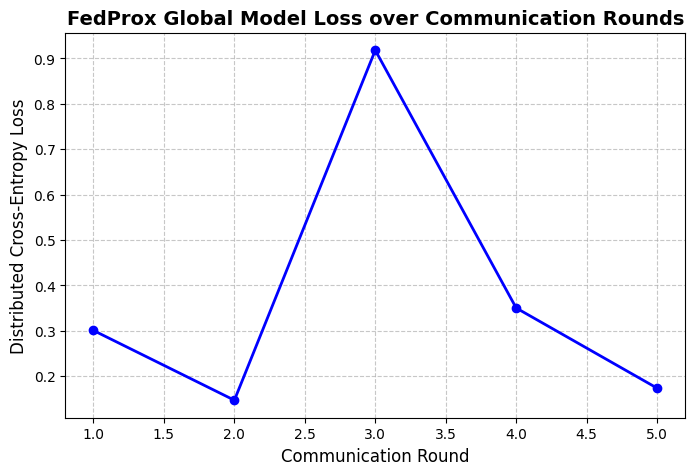

In [21]:
import flwr as fl
import matplotlib.pyplot as plt
import torch

print("Starting Federated Learning Simulation with 5 Clients (FedProx on CPU)...")

# === FIX 1: Device ke jor kore CPU kora holo jate GPU er jonno crash na kore ===
device = torch.device("cpu")

# ১. ক্লায়েন্ট তৈরির ফাংশন (প্রতিটি ক্লায়েন্ট একটি করে হাসপাতাল রিপ্রেজেন্ট করে)
def client_fn(cid: str) -> fl.client.Client:
    model = LightweightDNAClassifier().to(device)
    return FedProxGenomicClient(model, train_loader, test_loader, mu=0.01)

# ২. সার্ভার স্ট্র্যাটেজি
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=5,
    min_evaluate_clients=5,
    min_available_clients=5,
)

# ৩. সিমুলেশন শুরু
history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=5),
    strategy=strategy,
    # === FIX 2: num_gpus ke 0 kora holo jate Flower GPU share korte giye crash na kore ===
    client_resources={"num_cpus": 2, "num_gpus": 0},
)

print("\n=== FL Simulation Completed ===")

# ৪. ফেডারেটেড লার্নিংয়ের লস কার্ভ (Loss Curve) তৈরি করা
if history.losses_distributed:
    rounds, losses = zip(*history.losses_distributed)
    plt.figure(figsize=(8, 5))
    plt.plot(rounds, losses, marker='o', linestyle='-', color='b', linewidth=2)
    plt.title('FedProx Global Model Loss over Communication Rounds', fontsize=14, fontweight='bold')
    plt.xlabel('Communication Round', fontsize=12)
    plt.ylabel('Distributed Cross-Entropy Loss', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.savefig('fedprox_loss_curve.png', dpi=300, bbox_inches='tight')
    print("\nLoss curve saved as 'fedprox_loss_curve.png'")
    plt.show()

In [22]:
import time
import torch
import numpy as np

print("Measuring Inference Time (CPU vs GPU)...")

# একটি ডামি DNA সিকোয়েন্স তৈরি করা হচ্ছে (Batch Size 1, Seq Length 512)
dummy_input = torch.randint(0, 5, (1, 512))

def measure_inference_time(model, device_name, num_runs=300):
    device = torch.device(device_name)
    model = model.to(device)
    model.eval()
    dummy_data = dummy_input.to(device)

    # Warm-up (সঠিক সময় মাপার আগে মডেলকে রেডি করা, বিশেষ করে GPU এর জন্য এটি জরুরি)
    with torch.no_grad():
        for _ in range(50):
            _ = model(dummy_data)

    # GPU হলে সিঙ্ক্রোনাইজ করা
    if device_name == 'cuda':
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    # মেইন টেস্টিং লুপ
    with torch.no_grad():
        for _ in range(num_runs):
            _ = model(dummy_data)

    if device_name == 'cuda':
        torch.cuda.synchronize()

    end_time = time.perf_counter()

    # গড় সময় বের করা (মিলিসেকেন্ডে)
    avg_time_ms = ((end_time - start_time) / num_runs) * 1000
    return avg_time_ms

# ==========================================
# Lightweight Model-এর Inference মাপা
# ==========================================
light_cpu_time = measure_inference_time(light_model, 'cpu')
print(f"\n[Lightweight Model] CPU Inference Time: {light_cpu_time:.3f} ms / sample")

if torch.cuda.is_available():
    light_gpu_time = measure_inference_time(light_model, 'cuda')
    print(f"[Lightweight Model] GPU Inference Time: {light_gpu_time:.3f} ms / sample")
else:
    print("GPU is not available. Please enable GPU in Colab to measure GPU time.")

# ==========================================
# (Optional) Base Model-এর Inference মাপা (কম্পেয়ার করার জন্য)
# ==========================================
# base_cpu_time = measure_inference_time(opt_model, 'cpu')
# print(f"\n[Heavy Base Model] CPU Inference Time: {base_cpu_time:.3f} ms / sample")

Measuring Inference Time (CPU vs GPU)...

[Lightweight Model] CPU Inference Time: 5.134 ms / sample
GPU is not available. Please enable GPU in Colab to measure GPU time.
